# Rare Wine Handling: Class Weighting vs Oversampling

In both datasets most wines are quality 5 or 6, so all our models predict the rare wines (quality 3-4 and 8-9) badly. In this notebook we try 2 common ways to fix this on our 4 main models (Linear Regression, Random Forest, KNN and MLP).

- **Class weighting:** we give bigger weight to rare quality scores when training. The weight is 1 / (share of that score). "Soft" uses the square root of this weight so it is not too extreme.
- **Oversampling:** we copy the rare wines until each quality score is at least 10% of the training data.

KNN cannot use sample weights, so we only use oversampling for KNN. "Baseline" means the selected model trained normally, without any rare wine handling.

We use the same cleaning and split as the main notebook (remove duplicates, stratified 80/20 split, random_state = 42) and the same 5-fold CV on the training set. Weighting and oversampling are only used on the training folds, and the validation fold is always the original data.

## 1. Setup

In [1]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

base_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"

# load data, remove duplicates and split
def load_and_split(file_name):
    df = pd.read_csv(base_url + file_name, sep=";").drop_duplicates()
    X = df.drop(columns=["quality"])
    y = df["quality"]
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train, X_test, y_train, y_test = load_and_split("winequality-red.csv")
white_X_train, white_X_test, white_y_train, white_y_test = load_and_split("winequality-white.csv")

print("Red train:", X_train.shape, "| White train:", white_X_train.shape)

Red train: (1087, 11) | White train: (3168, 11)


## 2. Helper functions

In [2]:
# quality 3-4 or 8-9 = rare
# we check error for all wines, rare wines and normal (5-6) wines
def rare_eval(y_true, y_pred):
    y_true = np.asarray(y_true)
    rare = (y_true <= 4) | (y_true >= 8)
    typical = (y_true >= 5) & (y_true <= 6)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "Rare MAE": mean_absolute_error(y_true[rare], y_pred[rare]),
        "5-6 MAE": mean_absolute_error(y_true[typical], y_pred[typical]),
    }

# weight = 1 / (share of that quality score), power 0.5 is a soft version
def class_weights(y, power=1.0):
    share = y.map(y.value_counts(normalize=True))
    w = (1 / share) ** power
    return (w / w.mean()).values

# copy rare wines until each quality score is at least 10% of the training data
def oversample(X, y, min_share=0.10, seed=42):
    rng = np.random.RandomState(seed)
    X_parts, y_parts = [X], [y]
    for q, count in y.value_counts().items():
        need = int(min_share * len(y)) - count
        if need > 0:
            idx = rng.choice(np.where(y.values == q)[0], need, replace=True)
            X_parts.append(X.iloc[idx])
            y_parts.append(y.iloc[idx])
    return pd.concat(X_parts), pd.concat(y_parts)

## 3. Models

We use the 4 selected (tuned) models from Section 9 of the main notebook, with the same settings as the other extra notebooks. KNN and MLP have StandardScaler inside the pipeline.

In [3]:
# tuned settings from Section 9
def make_models(wine):
    rf_params = ({"n_estimators": 200, "max_depth": None, "min_samples_leaf": 3} if wine == "Red"
                 else {"n_estimators": 200, "max_depth": 20, "min_samples_leaf": 3})
    knn_k = 11 if wine == "Red" else 15
    return {
        "LR": lambda: LinearRegression(),
        "RF": lambda: RandomForestRegressor(**rf_params, random_state=42, n_jobs=-1),
        "KNN": lambda: Pipeline([("scaler", StandardScaler()),
                                 ("model", KNeighborsRegressor(n_neighbors=knn_k, weights="distance", p=1))]),
        "MLP": lambda: Pipeline([("scaler", StandardScaler()),
                                 ("model", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                                                        solver="adam", learning_rate_init=0.001, alpha=0.001,
                                                        max_iter=2000, early_stopping=True,
                                                        validation_fraction=0.15, n_iter_no_change=30,
                                                        random_state=42))]),
    }

# check if each model can use sample weights
# KNN can't, MLP depends on sklearn version
def supports_weight(model):
    est = model.named_steps["model"] if isinstance(model, Pipeline) else model
    return "sample_weight" in inspect.signature(est.fit).parameters

for name, make in make_models("Red").items():
    print(name, "supports sample weights:", supports_weight(make()))

LR supports sample weights: True
RF supports sample weights: True
KNN supports sample weights: False
MLP supports sample weights: False


## 4. 5-fold CV experiment

In [4]:
def fit_model(make, X, y, weights=None):
    model = make()
    if weights is None:
        return model.fit(X, y)
    if isinstance(model, Pipeline):
        return model.fit(X, y, model__sample_weight=weights)
    return model.fit(X, y, sample_weight=weights)

def run_rare_experiment(X_tr, y_tr, wine):
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    rows = []
    for name, make in make_models(wine).items():
        methods = ["Baseline"]
        if supports_weight(make()):
            methods += ["Weight (soft)", "Weight (full)"]
        methods += ["Oversample 10%"]

        for method in methods:
            fold_scores = []
            for tr_idx, va_idx in cv.split(X_tr):
                X_a, y_a = X_tr.iloc[tr_idx], y_tr.iloc[tr_idx]
                weights = None
                if method == "Weight (soft)":
                    weights = class_weights(y_a, 0.5)
                elif method == "Weight (full)":
                    weights = class_weights(y_a, 1.0)
                elif method == "Oversample 10%":
                    X_a, y_a = oversample(X_a, y_a)
                model = fit_model(make, X_a, y_a, weights)
                fold_scores.append(rare_eval(y_tr.iloc[va_idx], model.predict(X_tr.iloc[va_idx])))
            rows.append({"Model": name, "Method": method, **pd.DataFrame(fold_scores).mean().to_dict()})
    return pd.DataFrame(rows)

red_rare_df = run_rare_experiment(X_train, y_train, "Red")
white_rare_df = run_rare_experiment(white_X_train, white_y_train, "White")

print("Red wine (5-fold CV):")
display(red_rare_df.round(3))
print("White wine (5-fold CV):")
display(white_rare_df.round(3))

Red wine (5-fold CV):


,Model,Method,MAE,Rare MAE,5-6 MAE
0,LR,Baseline,0.516,1.465,0.400
1,LR,Weight (soft),0.566,1.162,0.506
2,LR,Weight (full),0.723,0.895,0.715
3,LR,Oversample 10%,0.593,1.077,0.543
4,RF,Baseline,0.491,1.431,0.386
5,RF,Weight (soft),0.497,1.342,0.407
6,RF,Weight (full),0.502,1.325,0.418
7,RF,Oversample 10%,0.510,1.343,0.412
8,KNN,Baseline,0.516,1.514,0.405
9,KNN,Oversample 10%,0.571,1.393,0.479


White wine (5-fold CV):


,Model,Method,MAE,Rare MAE,5-6 MAE
0,LR,Baseline,0.578,1.576,0.431
1,LR,Weight (soft),0.602,1.424,0.499
2,LR,Weight (full),0.755,1.282,0.705
3,LR,Oversample 10%,0.637,1.409,0.545
4,RF,Baseline,0.541,1.431,0.418
5,RF,Weight (soft),0.546,1.383,0.436
6,RF,Weight (full),0.544,1.379,0.439
7,RF,Oversample 10%,0.552,1.368,0.441
8,KNN,Baseline,0.554,1.541,0.424
9,KNN,Oversample 10%,0.606,1.417,0.505


## 5. Change from baseline

Negative numbers mean the error went down (better).

In [5]:
def change_from_baseline(df):
    out = []
    for name, part in df.groupby("Model", sort=False):
        base = part[part["Method"] == "Baseline"].iloc[0]
        for _, row in part[part["Method"] != "Baseline"].iterrows():
            out.append({"Model": name, "Method": row["Method"],
                        "MAE change": row["MAE"] - base["MAE"],
                        "Rare MAE change": row["Rare MAE"] - base["Rare MAE"],
                        "5-6 MAE change": row["5-6 MAE"] - base["5-6 MAE"]})
    return pd.DataFrame(out)

print("Red wine:")
display(change_from_baseline(red_rare_df).round(3))
print("White wine:")
display(change_from_baseline(white_rare_df).round(3))

Red wine:


,Model,Method,MAE change,Rare MAE change,5-6 MAE change
0,LR,Weight (soft),0.050,-0.303,0.106
1,LR,Weight (full),0.207,-0.570,0.315
2,LR,Oversample 10%,0.077,-0.388,0.143
3,RF,Weight (soft),0.007,-0.089,0.021
4,RF,Weight (full),0.011,-0.106,0.032
5,RF,Oversample 10%,0.019,-0.089,0.026
6,KNN,Oversample 10%,0.055,-0.121,0.074
7,MLP,Oversample 10%,0.037,-0.180,0.058


White wine:


,Model,Method,MAE change,Rare MAE change,5-6 MAE change
0,LR,Weight (soft),0.024,-0.152,0.068
1,LR,Weight (full),0.178,-0.294,0.274
2,LR,Oversample 10%,0.060,-0.167,0.114
3,RF,Weight (soft),0.004,-0.048,0.017
4,RF,Weight (full),0.003,-0.053,0.020
5,RF,Oversample 10%,0.010,-0.063,0.022
6,KNN,Oversample 10%,0.052,-0.125,0.082
7,MLP,Oversample 10%,0.070,-0.053,0.102


## 6. Graph: rare wine error vs overall error

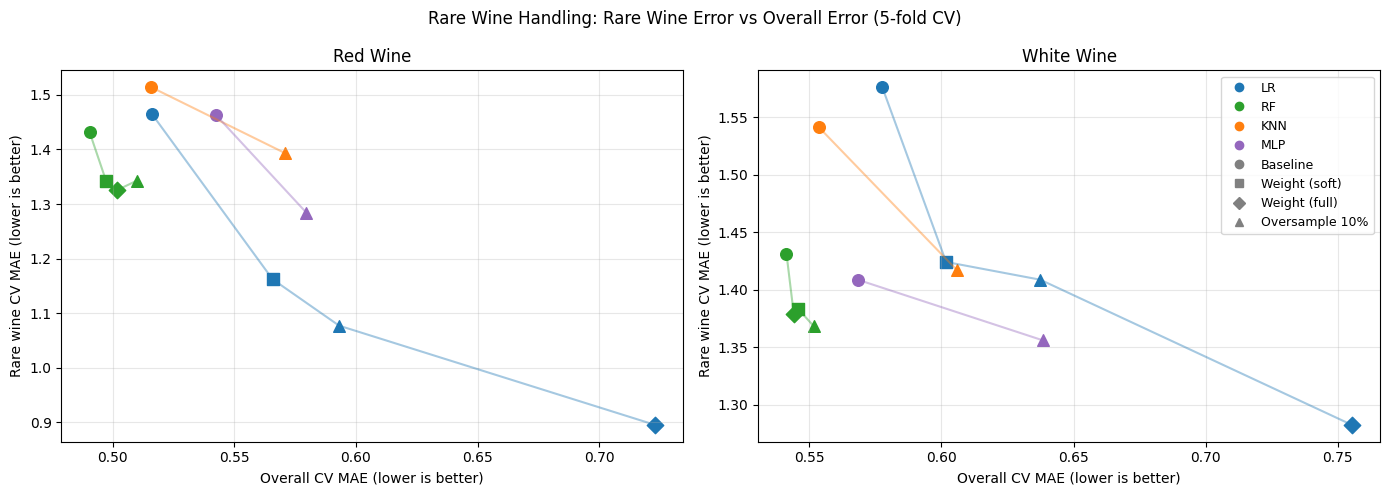

In [6]:
# x = overall error, y = rare wine error
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
colors = {"LR": "tab:blue", "RF": "tab:green", "KNN": "tab:orange", "MLP": "tab:purple"}
markers = {"Baseline": "o", "Weight (soft)": "s", "Weight (full)": "D", "Oversample 10%": "^"}

for ax, df, title in [(axes[0], red_rare_df, "Red Wine"), (axes[1], white_rare_df, "White Wine")]:
    for name, part in df.groupby("Model", sort=False):
        line = part.sort_values("MAE")
        ax.plot(line["MAE"], line["Rare MAE"], color=colors[name], alpha=0.4)
        for _, row in part.iterrows():
            ax.scatter(row["MAE"], row["Rare MAE"], color=colors[name], marker=markers[row["Method"]], s=70)
    ax.set_xlabel("Overall CV MAE (lower is better)")
    ax.set_ylabel("Rare wine CV MAE (lower is better)")
    ax.set_title(title)
    ax.grid(alpha=0.3)

from matplotlib.lines import Line2D
handles = [Line2D([], [], color=c, marker="o", linestyle="", label=n) for n, c in colors.items()]
handles += [Line2D([], [], color="grey", marker=m, linestyle="", label=n) for n, m in markers.items()]
axes[1].legend(handles=handles, loc="upper right", fontsize=9)
plt.suptitle("Rare Wine Handling: Rare Wine Error vs Overall Error (5-fold CV)")
plt.tight_layout()
plt.savefig("rare_wine_handling.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Summary

For all models, weighting and oversampling made the rare-wine error smaller, but the overall error and the 5–6 wine error got bigger, so there is a trade-off. RF was the most balanced one. Its rare-wine MAE went down by about 4–7%, and the overall MAE only went up by 0.003–0.019, so RF was still the best model even after weighting. LR changed the most. When we used full weighting on red wine, the rare-wine MAE went down from 1.465 to 0.895 (-39%), but the overall MAE went up from 0.516 to 0.723 (+40%). KNN and MLP cannot use sample weights, so we only tried oversampling for them. For these two models, the overall MAE got 7–12% worse, while the rare-wine MAE only improved by 4–12%. For RF, oversampling improved the rare wines about the same as weighting, but the overall MAE got worse more, so weighting was better for RF.